# Scheduling policies under a grid constraint

The office site gets a 35 kW grid connection for 20 × 3.7 kW points. All policies see
the same sampled vehicles, so differences come from the policy alone.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import elvis

plt.style.use("paper.mplstyle")
FIGURES = Path("output/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
office = elvis.load_preset("office")
site = office.replace(
    infrastructure=elvis.InfrastructureSpec.wallboxes(20, 3.7, transformer_power_kw=35)
)
realisation = site.realise(elvis.TimeGrid.create("2024-03-04", "2024-05-26 23:45", "15min"), 7)

policies = {
    "uncontrolled": "Uncontrolled",
    "fcfs": "First come, first served",
    "discrimination_free": "Discrimination-free",
}
results = {
    name: elvis.simulate(
        realisation.with_scenario(site.replace(operation=elvis.Operation(scheduling=name)))
    )
    for name in policies
}

pd.DataFrame({policies[name]: r.summary() for name, r in results.items()}).T.drop(
    columns="scenario"
)

,events,rejections,rejection_rate,energy_kwh,peak_load_kw,simultaneity_factor,mean_charging_hours
Uncontrolled,3000,1508,0.502667,24639.218075,74.0,1.0,4.581602
"First come, first served",3000,1508,0.502667,23910.3965,35.0,0.472973,4.81937
Discrimination-free,3000,1508,0.502667,23026.295,35.0,0.472973,6.020777


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


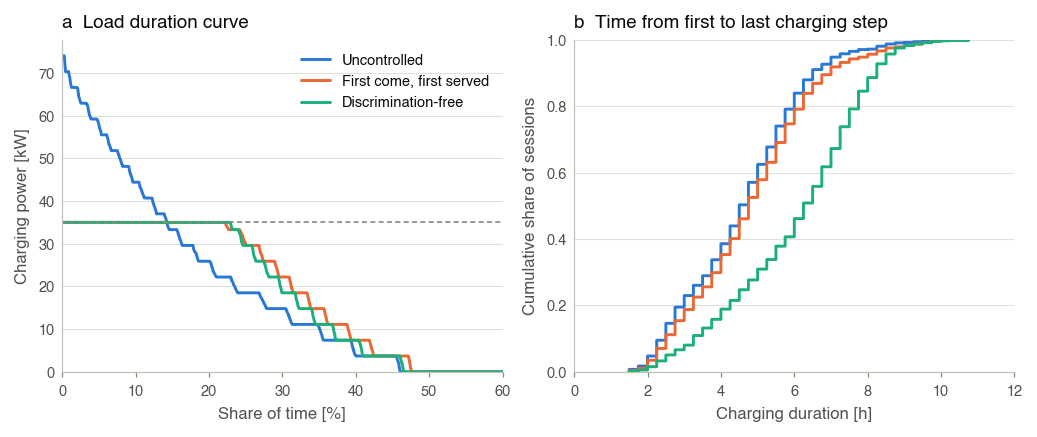

In [3]:
fig, (ax_ldc, ax_cdf) = plt.subplots(1, 2)

for (name, result), color in zip(results.items(), ["C0", "C1", "C2"], strict=True):
    duration = np.sort(result.load_profile_kw)[::-1]
    share = np.arange(1, len(duration) + 1) / len(duration) * 100
    ax_ldc.plot(share, duration, color=color, label=policies[name])

    hours = np.sort(result.charging_hours())
    ax_cdf.plot(
        hours,
        np.arange(1, len(hours) + 1) / len(hours),
        color=color,
        label=policies[name],
        drawstyle="steps-post",
    )

ax_ldc.axhline(35, color="#898781", linewidth=0.8, linestyle=(0, (3, 2)))
ax_ldc.annotate(
    "grid limit 35 kW",
    (100, 35),
    xytext=(0, 3),
    textcoords="offset points",
    ha="right",
    color="#52514e",
    fontsize=7,
)
ax_ldc.set_title("a  Load duration curve")
ax_ldc.set_xlabel("Share of time [%]")
ax_ldc.set_ylabel("Charging power [kW]")
ax_ldc.set_xlim(0, 60)
ax_ldc.set_ylim(0, None)
ax_ldc.legend(loc="upper right")

ax_cdf.set_title("b  Time from first to last charging step")
ax_cdf.set_xlabel("Charging duration [h]")
ax_cdf.set_ylabel("Cumulative share of sessions")
ax_cdf.set_xlim(0, 12)
ax_cdf.set_ylim(0, 1)

fig.savefig(FIGURES / "02_policies.pdf")